In [1]:
from pathlib import Path
import shutil
import os
import sys

INPUT = Path("/kaggle/input")

print('yeah')

# 1. Автоматически находим корень проекта по pyproject.toml + src/
CODE_ROOT = next(
    p.parent
    for p in INPUT.rglob("pyproject.toml")
    if (p.parent / "src").is_dir()
)
print('start')

# 2. Автоматически находим dataset с данными
DATA_ROOT = next(
    p
    for p in INPUT.rglob("data")
    if p.is_dir() and CODE_ROOT not in p.parents and p != CODE_ROOT / "data"
)

print("CODE_ROOT =", CODE_ROOT)
print("DATA_ROOT =", DATA_ROOT)

# 3. Копируем код в writable-папку
PROJECT_ROOT = Path("/kaggle/working/project")

if PROJECT_ROOT.exists():
    shutil.rmtree(PROJECT_ROOT)

shutil.copytree(CODE_ROOT, PROJECT_ROOT)

# 4. Подставляем Kaggle-данные вместо project/data
project_data = PROJECT_ROOT / "data"

if project_data.exists():
    if project_data.is_dir():
        shutil.rmtree(project_data)
    else:
        project_data.unlink()

project_data.symlink_to(DATA_ROOT, target_is_directory=True)

# 5. Переходим в проект
os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print()
print("READY")
print("cwd:", Path.cwd())
print("src:", (PROJECT_ROOT / "src").exists())
print("configs:", (PROJECT_ROOT / "configs").exists())
print("data ->", (PROJECT_ROOT / "data").resolve())

yeah
start
CODE_ROOT = /kaggle/input/datasets/sevaperetiatko/myfiles
DATA_ROOT = /kaggle/input/datasets/sevaperetiatko/mydata/data

READY
cwd: /kaggle/working/project
src: True
configs: True
data -> /kaggle/input/datasets/sevaperetiatko/mydata/data


# Две финальные AGMFA HardShift — фиксированные 22 эпохи
Свежая ImageNet V2 initialization для обеих моделей. Corrected AGMFA conv2 taps,
partial layer3/4, frozen BN, warmup3, прежние AdamW/LR/seed42, cosine T_max22.
Batch16 **объектов**: source → clean+hard (2 views), бывший val → только D4 (1 view).

**Train-only:** val только для отчёта; last.pt эпохи22 — финальный.
**Train+val:** бывший val получает только D4 и CE weight2, без synthetic corruptions.
Обычное shuffled объединение, каждый объект один раз за эпоху, никакого oversampling.
Loss = (sum(source losses)+2 sum(target CE))/(n_source+2 n_target).
Validation selection отсутствует; final.pt эпохи22. Старые checkpoints не используются.
22 эпохи заданы заранее; local peak эпохи14 не участвует в выборе.

Test читается только в ячейке с **RUN_TEST=True**. Две модели → ровно два CSV,
без TTA, ансамблей и автоматической отправки на Kaggle.


In [2]:
from pathlib import Path
import sys,json
import pandas as pd
import torch
from IPython.display import display

ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks':
    ROOT=ROOT.parent
if not (ROOT/'src').is_dir():
    raise RuntimeError('Укажите ROOT — корень проекта с src/configs')
if str(ROOT) not in sys.path:
    sys.path.insert(0,str(ROOT))
from src.experiment import load_config
from src.final_hardshift import run_final_hardshift,plot_final_history,make_final_submissions,validate_final_config
from src.utils import get_device
from src.hard_target_shift import PROFILES


In [3]:
RUN_TRAIN_ONLY=True
RUN_TRAIN_VAL=True
RUN_TEST=True

RAW_DIR=ROOT/'data/raw'  # Kaggle: каталог с train/val/test и CSV
DEVICE='auto'
BATCH_SIZE=16  # original objects, source batches ->32 views; reduce to8 if OOM
TEST_BATCH_SIZE=32
NUM_WORKERS=2
CPU_THREADS=4
if get_device(DEVICE).type=='cpu':
    torch.set_num_threads(CPU_THREADS)
workers=NUM_WORKERS if get_device(DEVICE).type=='cuda' else 0
TRAIN_CONFIG=ROOT/'configs/resnet50_agmfa_hardshift_final_train.json'
TRAIN_VAL_CONFIG=ROOT/'configs/resnet50_agmfa_hardshift_final_train_val.json'
cfg_train=load_config(TRAIN_CONFIG)
cfg_refit=load_config(TRAIN_VAL_CONFIG)
for cfg in (cfg_train,cfg_refit):
    cfg['data'].update(raw_dir=str(RAW_DIR),batch_size=BATCH_SIZE,num_workers=workers)
    cfg['training']['device']=DEVICE
    validate_final_config(cfg)
print('Device:',get_device(DEVICE),'| fixed epochs:',22)
print('Train-only:',cfg_train['exp_id'])
print('Train+val:',cfg_refit['exp_id'])
print('Test is disabled until RUN_TEST=True')


Device: cuda | fixed epochs: 22
Train-only: resnet50_agmfa_hardshift_final_train_001
Train+val: resnet50_agmfa_hardshift_final_train_val_001
Test is disabled until RUN_TEST=True


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 185MB/s] 


Epoch 1/22 | source clean=0.5493 hard=0.4321 CE=1.6572/1.9668 JS=0.0454 | target CE=None | val=0.7811158798283262 | LR={'backbone': 5e-05, 'head': 0.0005} | selection=fixed last epoch
Epoch 2/22 | source clean=0.8030 hard=0.6531 CE=0.7793/1.2112 JS=0.0687 | target CE=None | val=0.8297567954220315 | LR={'backbone': 4.9750625326082856e-05, 'head': 0.0004974604497492927} | selection=fixed last epoch
Epoch 4/22 | source clean=0.8834 hard=0.7453 CE=0.4206/0.8337 JS=0.0733 | target CE=None | val=0.882689556509299 | LR={'backbone': 4.77859838861857e-05, 'head': 0.0004774531828409524} | selection=fixed last epoch
Epoch 6/22 | source clean=0.9330 hard=0.8248 CE=0.2175/0.5470 JS=0.0627 | target CE=None | val=0.9370529327610873 | LR={'backbone': 4.401586457167933e-05, 'head': 0.0004390595188013875} | selection=fixed last epoch
Epoch 8/22 | source clean=0.9608 hard=0.8586 CE=0.1444/0.4492 JS=0.0583 | target CE=None | val=0.9298998569384835 | LR={'backbone': 3.874570002766214e-05, 'head': 0.0003853

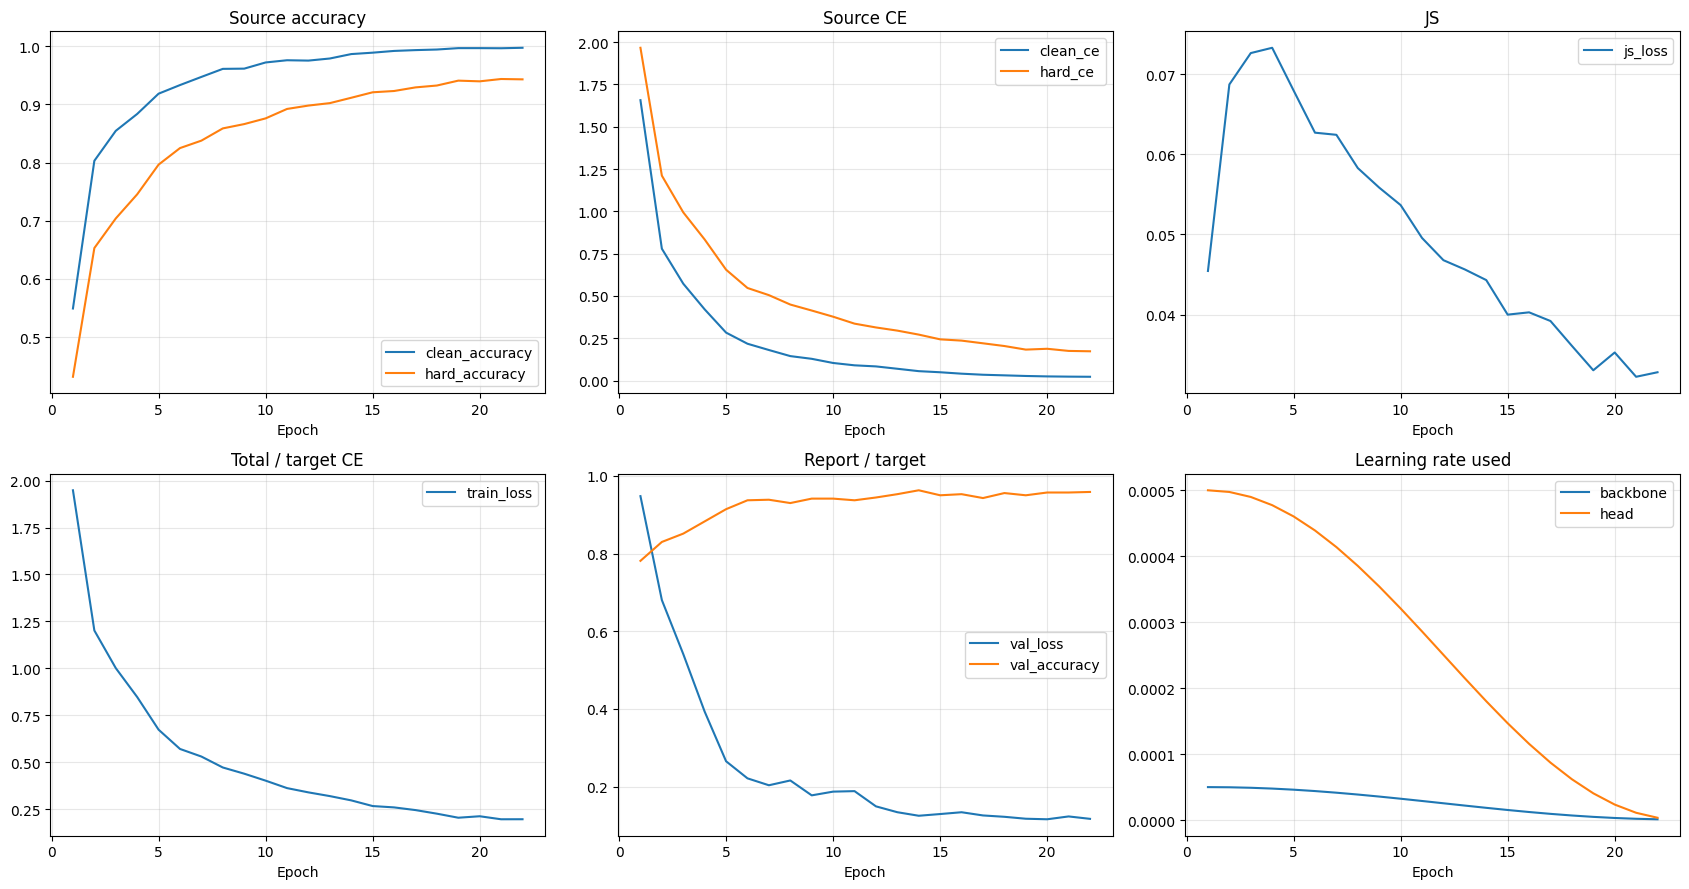

{'epochs': 22, 'checkpoint': 'last.pt', 'selection': 'fixed_last_epoch', 'val_accuracy': 0.9585121602288984, 'val_loss': 0.1167629345590635, 'train_time_min': 44.41125867401667}


In [4]:
if RUN_TRAIN_ONLY:
    train_result=run_final_hardshift(cfg_train,project_root=ROOT,show_plots=True)
    print(train_result['summary'])
    del train_result  # освобождаем модель перед вторым обучением
else:
    print('Train-only обучение выключено.')


Epoch 1/22 | source clean=0.5637 hard=0.4473 CE=1.5676/1.9039 JS=0.0508 | target CE=1.51406587597958 | val=none | LR={'backbone': 5e-05, 'head': 0.0005} | selection=fixed last epoch
Epoch 2/22 | source clean=0.8126 hard=0.6707 CE=0.7041/1.1464 JS=0.0744 | target CE=0.6931256797066083 | val=none | LR={'backbone': 4.9750625326082856e-05, 'head': 0.0004974604497492927} | selection=fixed last epoch
Epoch 4/22 | source clean=0.8926 hard=0.7467 CE=0.3684/0.7925 JS=0.0776 | target CE=0.33497994440434187 | val=none | LR={'backbone': 4.77859838861857e-05, 'head': 0.0004774531828409524} | selection=fixed last epoch
Epoch 6/22 | source clean=0.9382 hard=0.8286 CE=0.1981/0.5417 JS=0.0673 | target CE=0.15122282589304314 | val=none | LR={'backbone': 4.401586457167933e-05, 'head': 0.0004390595188013875} | selection=fixed last epoch
Epoch 8/22 | source clean=0.9580 hard=0.8570 CE=0.1333/0.4451 JS=0.0606 | target CE=0.07968218100656131 | val=none | LR={'backbone': 3.874570002766214e-05, 'head': 0.00038

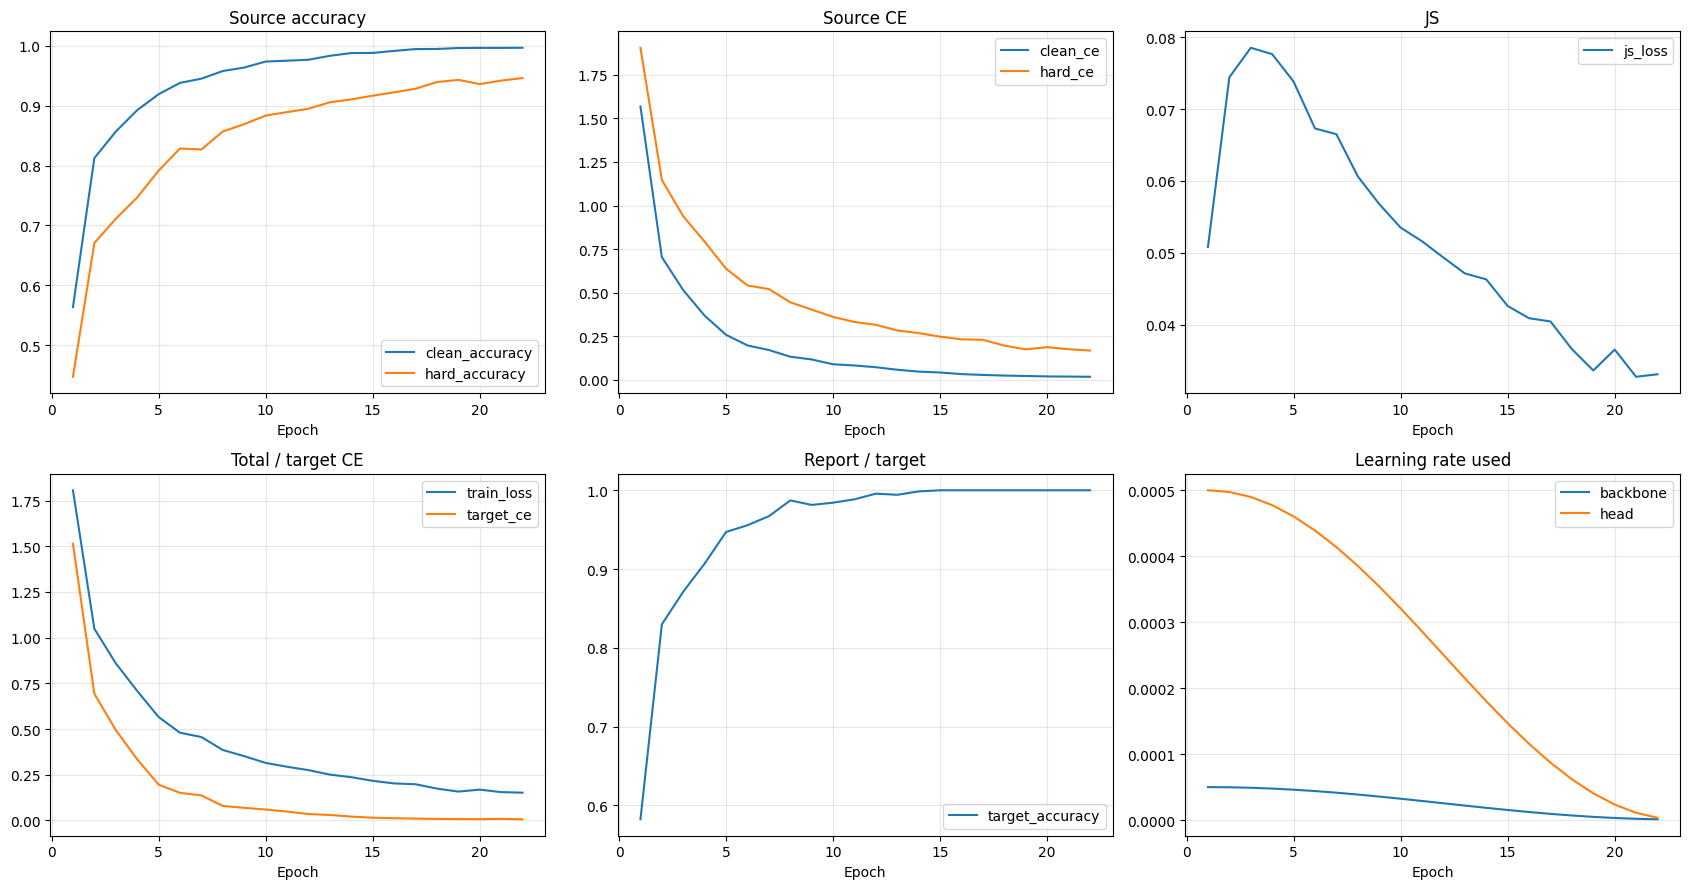

{'epochs': 22, 'checkpoint': 'final.pt', 'selection': 'fixed_last_epoch', 'val_accuracy': None, 'val_loss': None, 'train_time_min': 45.889057995616675}


In [5]:
if RUN_TRAIN_VAL:
    refit_result=run_final_hardshift(cfg_refit,project_root=ROOT,show_plots=True)
    print(refit_result['summary'])
    del refit_result
else:
    print('Train+val обучение выключено.')


## Сохранённые curves и аудит coverage
История каждого run: source clean/hard CE и Accuracy, JS, общий loss, LR.
Train+val дополнительно target CE/Accuracy; train-only — отчётная val loss/Accuracy.
Никакие val показатели не выбирают checkpoint и не управляют scheduler.
Profile counts касаются **только source**. Проверка once-per-epoch для каждого
source и target выполняется внутри training loop. В 22 эпохах три полных
6-эпоховых цикла и четыре эпохи следующего цикла.


,exp_id,epochs,checkpoint,selection,val_accuracy,val_loss,train_time_min
0,resnet50_agmfa_hardshift_final_train_001,22,last.pt,fixed_last_epoch,0.958512,0.116763,44.411259


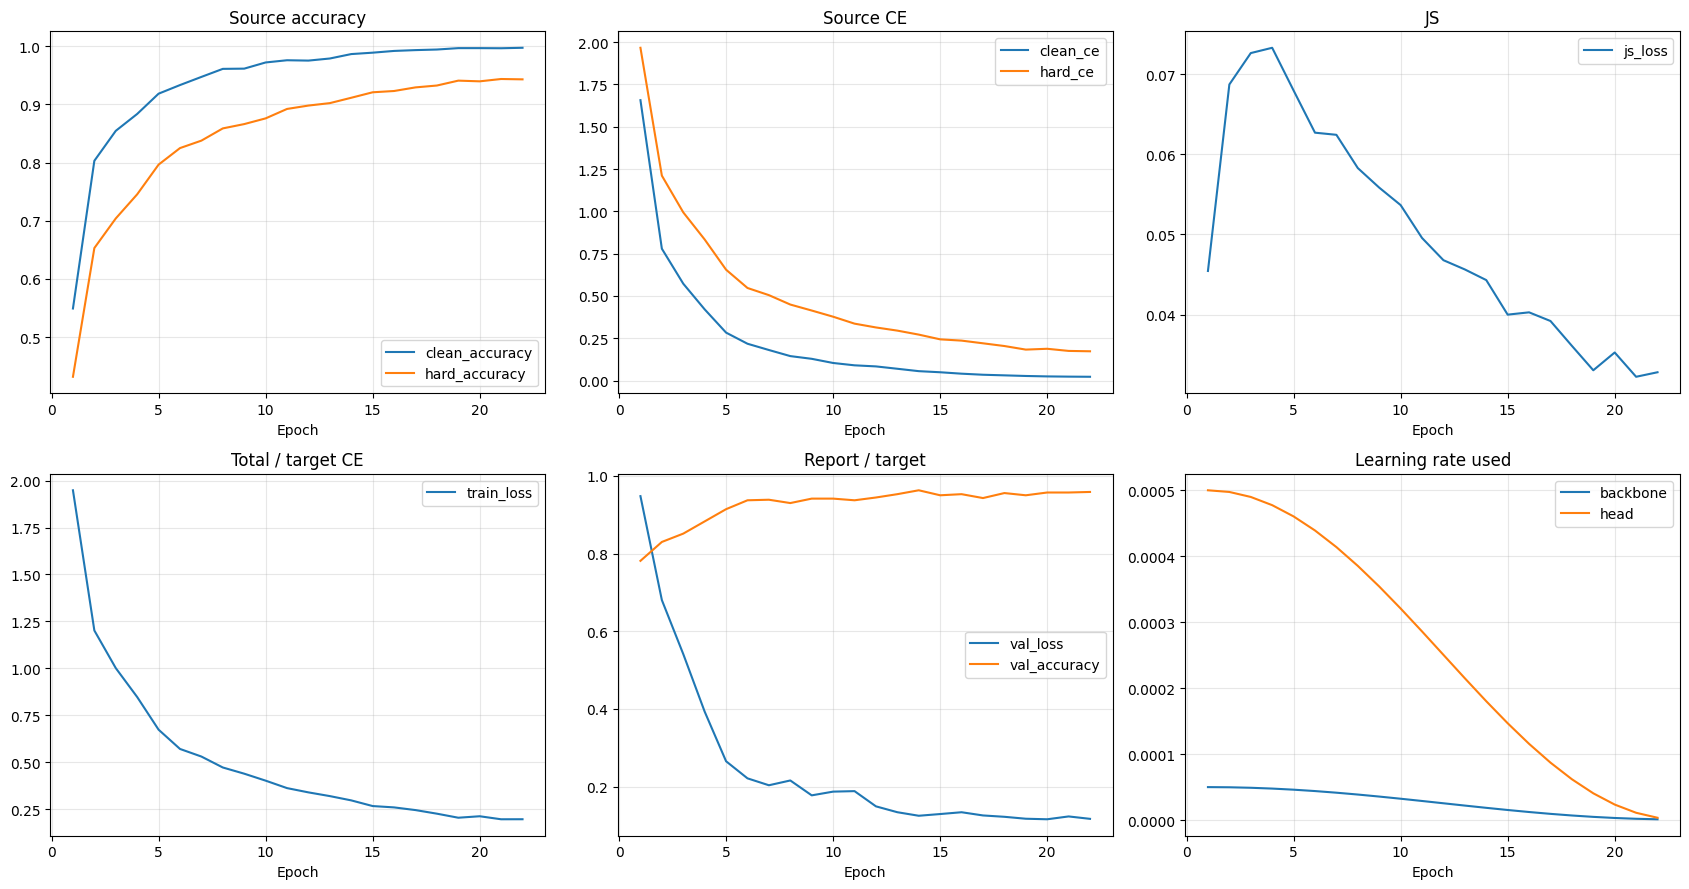

profile,artifact_noise,blur_lowres,dark_gray,dusk_color_cast,haze_lowcontrast,off_nadir
epoch,,,,,,
1,833,834,833,833,833,833
2,833,833,833,834,833,833
3,833,833,833,833,834,833
4,833,833,833,833,833,834
5,834,833,833,833,833,833
6,833,833,834,833,833,833
7,833,834,833,833,833,833
8,833,833,833,834,833,833
9,833,833,833,833,834,833


,exp_id,epochs,checkpoint,selection,val_accuracy,val_loss,train_time_min
0,resnet50_agmfa_hardshift_final_train_val_001,22,final.pt,fixed_last_epoch,None,None,45.889058


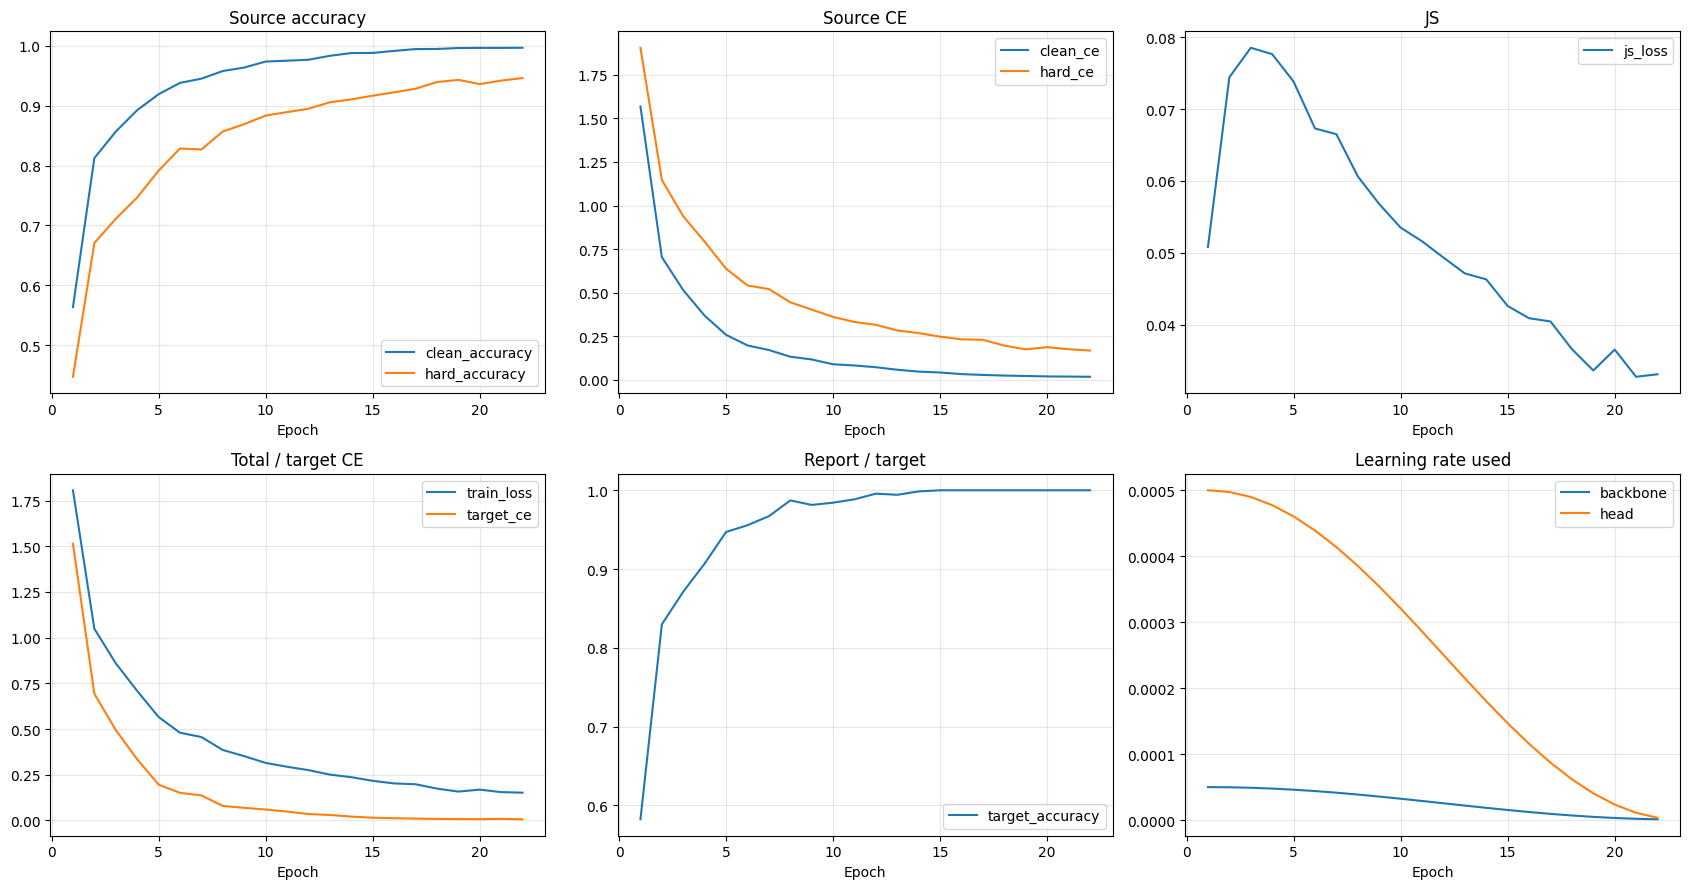

profile,artifact_noise,blur_lowres,dark_gray,dusk_color_cast,haze_lowcontrast,off_nadir
epoch,,,,,,
1,833,834,833,833,833,833
2,833,833,833,834,833,833
3,833,833,833,833,834,833
4,833,833,833,833,833,834
5,834,833,833,833,833,833
6,833,833,834,833,833,833
7,833,834,833,833,833,833
8,833,833,833,834,833,833
9,833,833,833,833,834,833


In [6]:
for cfg in (cfg_train,cfg_refit):
    logs=ROOT/'artifacts/logs'/cfg['exp_id']
    if not (logs/'summary.json').is_file():
        print(cfg['exp_id'],': ещё не завершён')
        continue
    summary=json.loads((logs/'summary.json').read_text())
    history=pd.read_csv(logs/'history.csv')
    counts=pd.read_csv(logs/'profile_counts.csv')
    metadata=json.loads((logs/'metadata.json').read_text())
    assert summary['epochs']==22 and summary['selection']=='fixed_last_epoch'
    assert history.epoch.tolist()==list(range(1,23))
    assert metadata['target_transforms']=='D4 only; no hard profile'
    assert not metadata['test_read']
    for epoch in range(1,23):
        expected=pd.Series([(i+epoch)%6 for i in range(4999)]).value_counts().reindex(range(6),fill_value=0)
        actual=counts[counts.epoch==epoch].set_index('profile').reindex(PROFILES)['count'].to_numpy()
        assert (actual==expected.to_numpy()).all()
    if cfg['final_hardshift']['training_splits']==['train','val']:
        assert history.source_samples.eq(4999).all() and history.target_samples.eq(699).all()
        assert not any(name.startswith('val_') for name in history.columns)
    else:
        assert history.target_samples.eq(0).all()
    display(pd.DataFrame([{'exp_id':cfg['exp_id'],**summary}]))
    plot_final_history(history,show=True)
    display(counts.pivot(index='epoch',columns='profile',values='count'))


## Test inference — две submissions
Веса должны быть в artifacts/models/<exp_id>/:
train-only **last.pt**, train+val **final.pt**. Можно выполнить эту часть отдельно
после загрузки весов, не включая flags обучения.
Когда обе модели готовы, включите RUN_TEST=True и выполните следующую ячейку.
CSV появятся в **ROOT/submissions/**:

- submission_agmfa_hardshift_train.csv
- submission_agmfa_hardshift_train_val.csv

Test probabilities: artifacts/predictions/<exp_id>/test_probabilities.npz;
предсказания в test.csv. NPZ и submission имеют sample submission order.
Проверяются 8299 уникальных IDs, отсутствие пропусков/дублей и argmax labels.
Inference records добавляются в experiments.csv отдельно от записей обучения.
Существующие outputs не перезаписываются. Kaggle upload выполняется вручную.


In [7]:
if RUN_TEST:
    submissions=make_final_submissions(cfg_train,cfg_refit,project_root=ROOT,
        raw_dir=RAW_DIR,device=DEVICE,batch_size=TEST_BATCH_SIZE,num_workers=workers)
    display(submissions)
else:
    print('Test не читается. RUN_TEST=False.')


,submission,probabilities
0,/kaggle/working/project/submissions/submission...,/kaggle/working/project/artifacts/predictions/...
1,/kaggle/working/project/submissions/submission...,/kaggle/working/project/artifacts/predictions/...


In [10]:
from pathlib import Path
import shutil
import zipfile

ARTIFACTS = Path("/kaggle/working/project/artifacts")
EXP_ID = "resnet50_agmfa_hardshift_final_train_val_001"
OUTPUT_DIR = Path("/kaggle/working")

# logs и predictions как раньше
targets = {
    "logs": ARTIFACTS / "logs" / EXP_ID,
    "predictions": ARTIFACTS / "predictions" / EXP_ID,
}

for name, folder in targets.items():
    if not folder.exists():
        print(f"SKIP: {folder} не существует")
        continue

    output_base = OUTPUT_DIR / f"{EXP_ID}_{name}"

    shutil.make_archive(
        str(output_base),
        "zip",
        root_dir=folder
    )

    print(f"Created: {output_base}.zip")


# models отдельно: best и last
models_dir = ARTIFACTS / "models" / EXP_ID

if models_dir.exists():
    for model_type in ["last"]:
        files = [
            p for p in models_dir.rglob("*")
            if p.is_file() and model_type.lower() in p.name.lower()
        ]

        if not files:
            print(f"SKIP: model '{model_type}' не найден")
            continue

        zip_path = OUTPUT_DIR / f"{EXP_ID}_{model_type}.zip"

        with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
            for file in files:
                z.write(
                    file,
                    arcname=file.relative_to(models_dir)
                )

        print(f"Created: {zip_path}")
else:
    print(f"SKIP: {models_dir} не существует")

Created: /kaggle/working/resnet50_agmfa_hardshift_final_train_val_001_logs.zip
Created: /kaggle/working/resnet50_agmfa_hardshift_final_train_val_001_predictions.zip
Created: /kaggle/working/resnet50_agmfa_hardshift_final_train_val_001_last.zip
